In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_predicted = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_rf.npy")
y_predicted_probs = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_probs_rf.npy")

y_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\y_test")
x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_test")

In [2]:
import joblib

rf_model = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Saved_Models\rf_model")

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Classification Report
print(classification_report(y_test, y_predicted))

              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1035
           1       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



Accuracy : ~76%

Precision : ~54%

Recall : ~78%

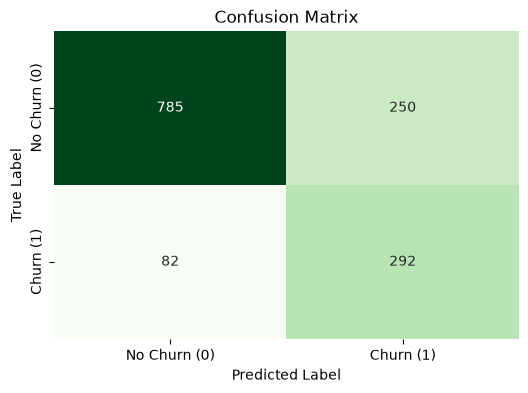

In [6]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_predicted)
plt.figure(figsize = (6,4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Greens', cbar = False, xticklabels = ['No Churn (0)', 'Churn (1)'], yticklabels = ['No Churn (0)', 'Churn (1)'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

- Out of 374 Positive class data points, 292 were correctly identified and labelled, and 82 data points were falsely classified as negative class.
- Out of 1035 Negative class data points, 250 data points were falsely labelled as positive class.

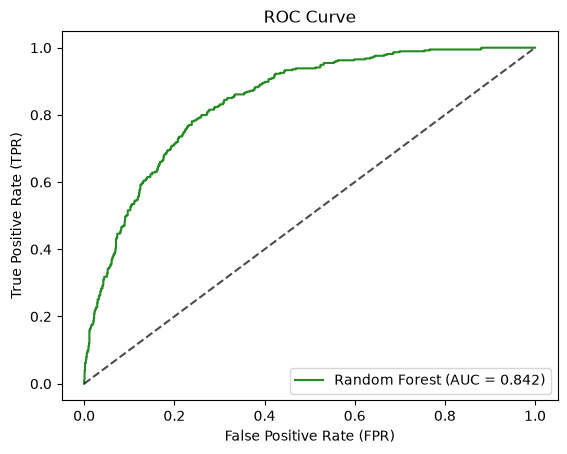

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_predicted_probs)
plt.plot(fpr, tpr, color = 'forestgreen', label = f"Random Forest (AUC = {roc_auc_score(y_test, y_predicted_probs) :.3f})")
plt.plot([0,1], [0,1], 'k--', alpha = 0.7)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc = 'lower right')

plt.show()

ROC_AUC Score => 0.842 (slightly worse than Logistic Regression model performance)

C:\Users\dhanu\AppData\Local\Temp\ipykernel_15032\262711403.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'viridis')


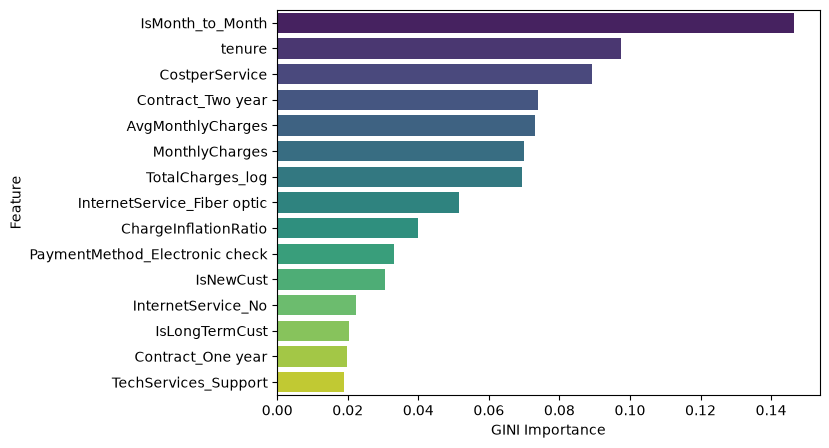

In [10]:
feature_imp = pd.DataFrame({
    'Feature' : x_test.columns, 
    'Importance' : rf_model.feature_importances_
}).sort_values(by = "Importance" ,ascending = False)

plt.figure(figsize = (7,5))
sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'viridis')
plt.xlabel("GINI Importance")
plt.ylabel("Feature")
plt.show()


The above features (aspects of the service) strongly affect the chances of customer Churn, so proper attention should be provided to these aspects that suits towards customer's favor so as to retain the customer and decrease any form of dissatisfaction.